# Tarea: Modelo de Ising y Empaquetamiento aleatorio

## Parte 1 – Modelo de Ising (algoritmo de Metrópolis)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---------- Modelo de Ising 2D, red cuadrada con condiciones periódicas ----------
J = 1.0   # constante de acoplamiento
B = 0.0   # campo externo (no aparece en el código porque B = 0)

@njit(cache=True)
def seed(n):
    np.random.seed(n)

@njit(cache=True)
def sweep(s, T, J):
    """Un paso de Monte Carlo = L*L intentos de volteo (Metrópolis)."""
    L = s.shape[0]
    for _ in range(L*L):
        i = np.random.randint(L); j = np.random.randint(L)
        vecinos = s[(i+1)%L, j] + s[(i-1)%L, j] + s[i, (j+1)%L] + s[i, (j-1)%L]
        dE = 2.0*J*s[i, j]*vecinos            # cambio de energía si volteamos s[i,j]
        if dE <= 0 or np.random.random() < np.exp(-dE/T):
            s[i, j] = -s[i, j]

@njit(cache=True)
def energia(s, J):
    """Energía total H = -J sum_<ij> s_i s_j (cada par se cuenta una vez)."""
    L = s.shape[0]; E = 0.0
    for i in range(L):
        for j in range(L):
            E -= J*s[i, j]*(s[(i+1)%L, j] + s[i, (j+1)%L])
    return E

@njit(cache=True)
def simular(s, T, J, pasos):
    """Corre 'pasos' pasos de Monte Carlo y regresa E(t) y M(t) (totales)."""
    E = np.empty(pasos); M = np.empty(pasos)
    for k in range(pasos):
        sweep(s, T, J)
        E[k] = energia(s, J)
        M[k] = s.sum()
    return E, M

def red_aleatoria(L):
    return np.where(np.random.rand(L, L) < 0.5, -1, 1).astype(np.int64)

### 1.1 Configuraciones finales y evolución de $E$ y $M$ para $T=1.5,\;2.3,\;3$

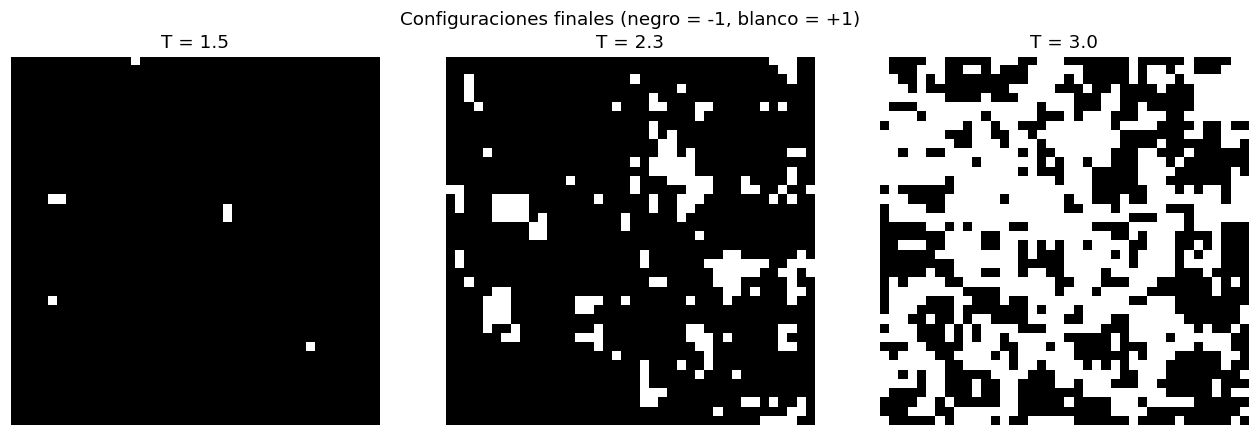

In [2]:
seed(42); np.random.seed(42)
L = 40; N = L*L
pasos = 6000
temps = [1.5, 2.3, 3.0]
configs, series = {}, {}

# Protocolo: arranque aleatorio a T=3 y se enfría 3 -> 2.3 -> 1.5 reutilizando la configuración
# (evita quedar atrapado en estados metaestables con paredes de dominio a T baja).
s = red_aleatoria(L)
for T in sorted(temps, reverse=True):
    E, M = simular(s, T, J, pasos)
    configs[T] = s.copy(); series[T] = (E/N, M/N)   # por espín

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, T in zip(ax, temps):
    a.imshow(configs[T], cmap="gray", interpolation="nearest")
    a.set_title(f"T = {T}"); a.axis("off")
plt.suptitle("Configuraciones finales (negro = -1, blanco = +1)")
plt.tight_layout(); plt.show()

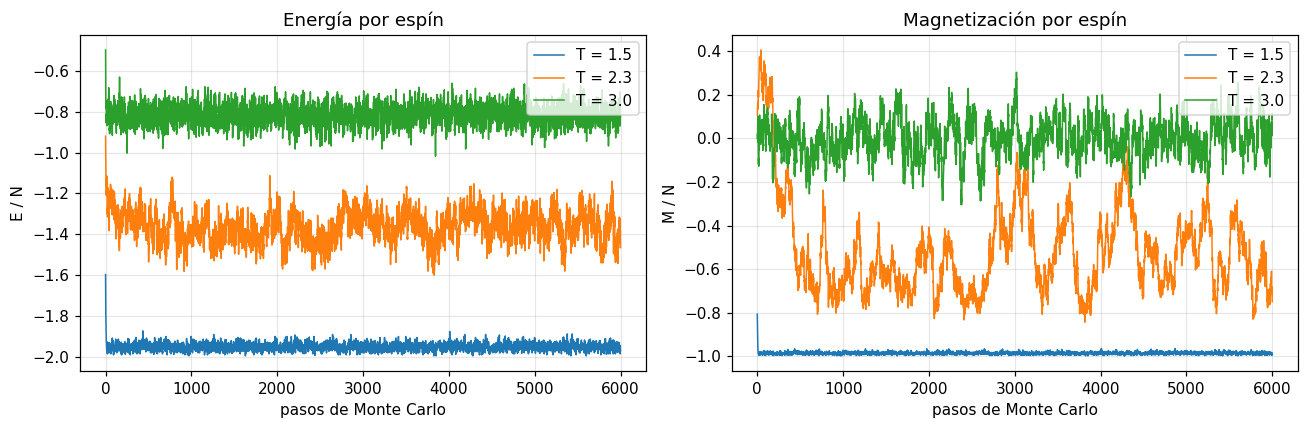

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for T in temps:
    e, m = series[T]
    ax[0].plot(e, label=f"T = {T}", lw=1)
    ax[1].plot(m, label=f"T = {T}", lw=1)
ax[0].set_xlabel("pasos de Monte Carlo"); ax[0].set_ylabel("E / N"); ax[0].set_title("Energía por espín")
ax[1].set_xlabel("pasos de Monte Carlo"); ax[1].set_ylabel("M / N"); ax[1].set_title("Magnetización por espín")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

### 1.2 Promedios y varianzas usando solo el estado estacionario

In [4]:
burn = 1500   # pasos descartados (termalización), se justifica con las gráficas anteriores
print(f"{'T':>5} {'<E>/N':>10} {'<|M|>/N':>10} {'Var(E/N)':>12} {'Var(|M|/N)':>12}")
for T in temps:
    e, m = series[T]
    e = e[burn:]; m = np.abs(m[burn:])
    print(f"{T:5.2f} {e.mean():10.4f} {m.mean():10.4f} {e.var():12.3e} {m.var():12.3e}")

    T      <E>/N    <|M|>/N     Var(E/N)   Var(|M|/N)
 1.50    -1.9509     0.9865    2.840e-04    2.558e-05
 2.30    -1.3639     0.5383    5.461e-03    2.604e-02
 3.00    -0.8163     0.0702    2.311e-03    3.010e-03


### 1.3 Barrido en temperatura entre $T=1.5$ y $T=3$

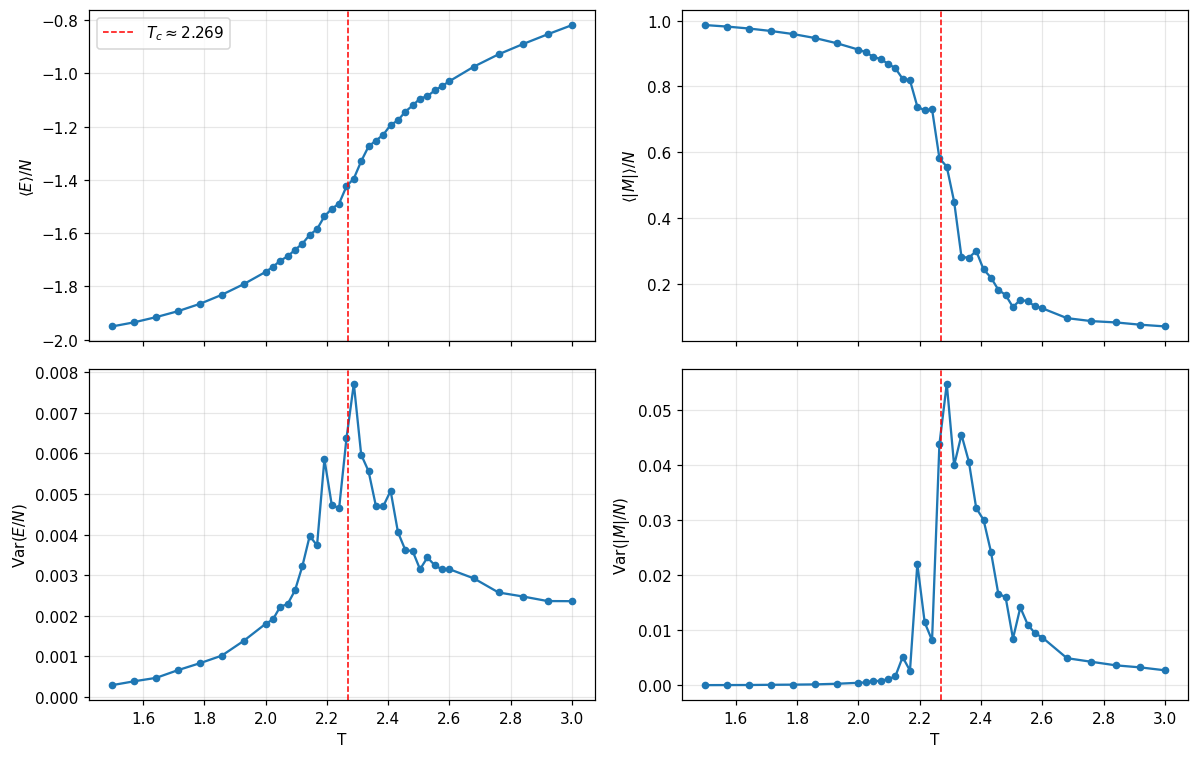

T donde Var(E) es máxima: 2.2880000000000003 | T donde Var(|M|) es máxima: 2.2880000000000003


In [5]:
L = 40; N = L*L
pasos, burn = 8000, 3000
Ts = np.concatenate([np.linspace(3.0, 2.6, 5, endpoint=False),
                     np.linspace(2.6, 2.0, 25, endpoint=False),
                     np.linspace(2.0, 1.5, 8)])      # más puntos cerca de Tc

s = red_aleatoria(L)
Em, Mm, Ev, Mv = [], [], [], []
for T in Ts:                       # se enfría gradualmente reutilizando la configuración anterior
    E, M = simular(s, T, J, pasos)
    e = E[burn:]/N; m = np.abs(M[burn:])/N
    Em.append(e.mean()); Mm.append(m.mean()); Ev.append(e.var()); Mv.append(m.var())
Em, Mm, Ev, Mv = map(np.array, (Em, Mm, Ev, Mv))

fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
datos = [(Em, r"$\langle E\rangle/N$"), (Mm, r"$\langle |M|\rangle/N$"),
         (Ev, r"Var$(E/N)$"), (Mv, r"Var$(|M|/N)$")]
for a, (y, nom) in zip(ax.ravel(), datos):
    a.plot(Ts, y, "o-", ms=4); a.axvline(2.269, color="r", ls="--", lw=1, label=r"$T_c\approx2.269$")
    a.set_ylabel(nom)
ax[0,0].legend()
ax[1,0].set_xlabel("T"); ax[1,1].set_xlabel("T")
plt.tight_layout(); plt.show()

iT = Ts[np.argmax(Ev)], Ts[np.argmax(Mv)]
print("T donde Var(E) es máxima:", iT[0], "| T donde Var(|M|) es máxima:", iT[1])

## Parte 2 – Empaquetamiento aleatorio de discos (recocido simulado)

In [6]:
import time

@njit(cache=True)
def energia_disco(k, xk, yk, x, y, r, L):
    """Energía de traslape del disco k si estuviera en (xk, yk): suma de (traslape)^2 con
    los demás discos y con las 4 paredes."""
    e = 0.0
    for j in range(x.shape[0]):
        if j == k: continue
        d = np.sqrt((xk - x[j])**2 + (yk - y[j])**2)
        o = r[k] + r[j] - d
        if o > 0: e += o*o
    o = r[k] - xk
    if o > 0: e += o*o
    o = xk + r[k] - L
    if o > 0: e += o*o
    o = r[k] - yk
    if o > 0: e += o*o
    o = yk + r[k] - L
    if o > 0: e += o*o
    return e

@njit(cache=True)
def energia_total(x, y, r, L):
    e = 0.0
    N = x.shape[0]
    for i in range(N):
        for j in range(i+1, N):
            d = np.sqrt((x[i]-x[j])**2 + (y[i]-y[j])**2)
            o = r[i] + r[j] - d
            if o > 0: e += o*o
        for o in (r[i]-x[i], x[i]+r[i]-L, r[i]-y[i], y[i]+r[i]-L):
            if o > 0: e += o*o
    return e

@njit(cache=True)
def recocido(x, y, r, L, T0, Tf, nT, sweeps_por_T, d0, tol, hist):
    """Recocido simulado a lado L fijo. Función objetivo U = energía de traslape.
    Paso: se mueve un disco al azar un desplazamiento uniforme en [-delta, delta]^2,
    con delta ~ d0*sqrt(T/T0). Aceptación de Metrópolis exp(-dU/T). Enfriamiento geométrico.
    Se detiene en cuanto U < tol (sin traslapes)."""
    N = x.shape[0]
    U = energia_total(x, y, r, L)
    alpha = (Tf/T0)**(1.0/(nT-1))
    T = T0; k = 0
    for it in range(nT):
        delta = max(d0*np.sqrt(T/T0), 1e-3)
        for s in range(sweeps_por_T):
            for m in range(N):
                i = np.random.randint(N)
                xn = x[i] + delta*(2*np.random.random()-1)
                yn = y[i] + delta*(2*np.random.random()-1)
                dU = energia_disco(i, xn, yn, x, y, r, L) - energia_disco(i, x[i], y[i], x, y, r, L)
                if dU <= 0 or np.random.random() < np.exp(-dU/T):
                    x[i] = xn; y[i] = yn; U += dU
            hist[k] = U; k += 1
            if U < tol:
                U = energia_total(x, y, r, L)      # se recalcula para evitar error acumulado
                if U < tol: return U, k
        T *= alpha
    return U, k

**Estrategia.** El objetivo es minimizar el lado $L$ del cuadrado. Para un $L$ fijo se define la función objetivo $U=\sum_{i<j}\max(0,r_i+r_j-d_{ij})^2+\sum_i(\text{traslapes con paredes})^2$, que vale 0 si y solo si no hay traslapes. Se corre recocido simulado hasta $U=0$; si lo logra se reduce $L$ (y se reescalan las posiciones), y si no, se reduce el tamaño del encogimiento hasta converger.

In [7]:
np.random.seed(7); seed(7)
r = np.concatenate([1.0*np.ones(100), 0.17*np.ones(70)])
N = len(r)
A_discos = np.sum(np.pi*r**2)

L = 30.0
x = np.random.rand(N)*L; y = np.random.rand(N)*L
buf = np.zeros(2_000_000)

xb, yb, Lb = x.copy(), y.copy(), L
paso_enc, fallos = 0.03, 0
historia, marcas, Ls_ok = [], [], []      # U(t), instantes donde se cambia L, L aceptados
t0 = time.time()
while paso_enc > 2e-4:
    U, k = recocido(x, y, r, L, 0.02, 1e-5, 300, 40, 0.6, 1e-12, buf)
    historia.append(buf[:k].copy()); marcas.append(sum(len(h) for h in historia))
    if U < 1e-12:
        xb, yb, Lb = x.copy(), y.copy(), L; fallos = 0; Ls_ok.append(L)
    else:
        fallos += 1
        if fallos >= 3: paso_enc /= 2; fallos = 0
    L = Lb*(1 - paso_enc)
    x = xb*(L/Lb); y = yb*(L/Lb)          # se reescala la configuración válida anterior
print(f"Tiempo: {time.time()-t0:.1f} s,  L mínimo sin traslapes = {Lb:.4f}")

Tiempo: 77.3 s,  L mínimo sin traslapes = 20.8624


In [8]:
x, y, L = xb, yb, Lb
phi = A_discos/L**2
print(f"Área de los discos = {A_discos:.3f}")
print(f"Lado mínimo L = {L:.4f}  ->  área de la caja = {L**2:.3f}")
print(f"Fracción de empaquetamiento Phi = {phi:.4f}")
print("Energía de traslape final:", energia_total(x, y, r, L))
# verificación independiente
dmin = min(np.hypot(x[i]-x[j], y[i]-y[j]) - r[i] - r[j] for i in range(N) for j in range(i+1, N))
pared = min((x-r).min(), (L-x-r).min(), (y-r).min(), (L-y-r).min())
print(f"Mínima separación entre discos = {dmin:.2e},  mínima distancia a la pared = {pared:.2e}")

Área de los discos = 320.515
Lado mínimo L = 20.8624  ->  área de la caja = 435.238
Fracción de empaquetamiento Phi = 0.7364
Energía de traslape final: 0.0
Mínima separación entre discos = 1.56e-04,  mínima distancia a la pared = 3.58e-03


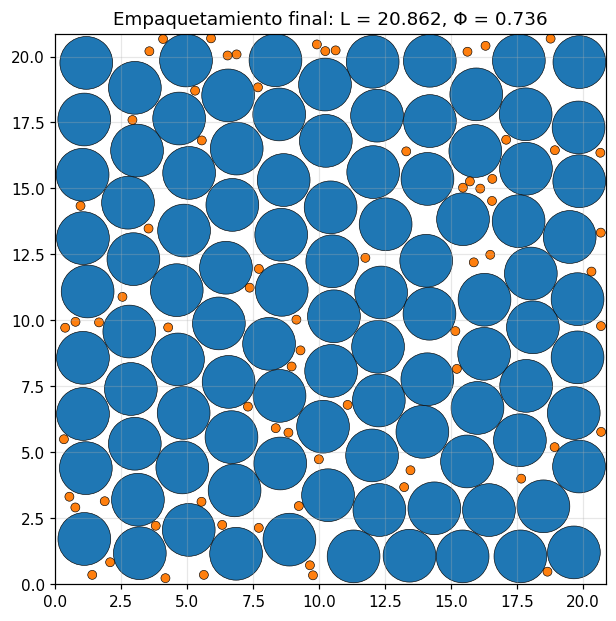

In [9]:
from matplotlib.patches import Circle
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for xi, yi, ri in zip(x, y, r):
    ax.add_patch(Circle((xi, yi), ri, fc="tab:blue" if ri == 1 else "tab:orange", ec="k", lw=0.4))
ax.set_xlim(0, L); ax.set_ylim(0, L); ax.set_aspect("equal")
ax.set_title(f"Empaquetamiento final: L = {L:.3f}, Φ = {phi:.3f}")
plt.show()

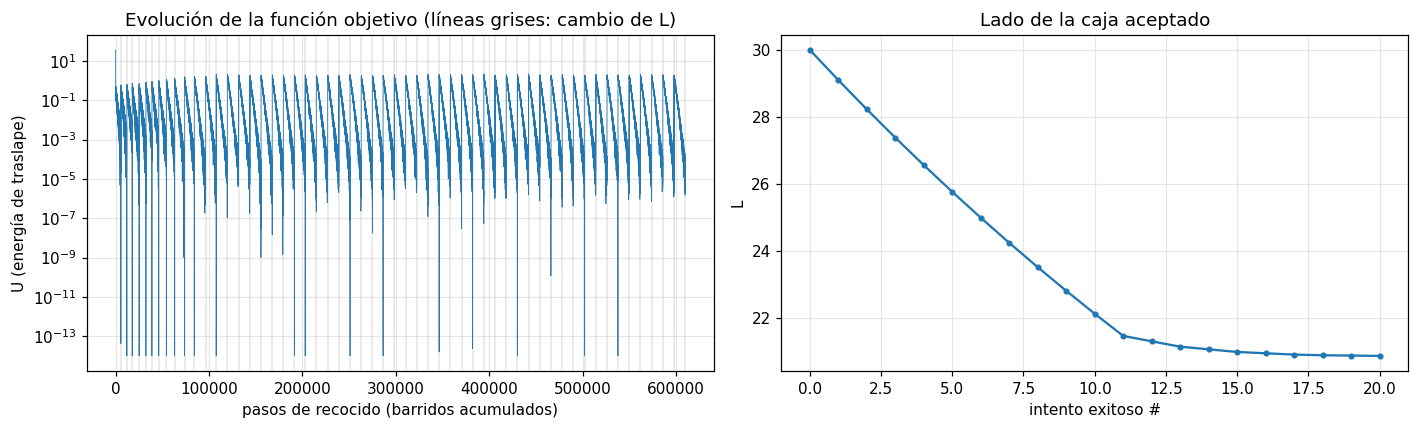

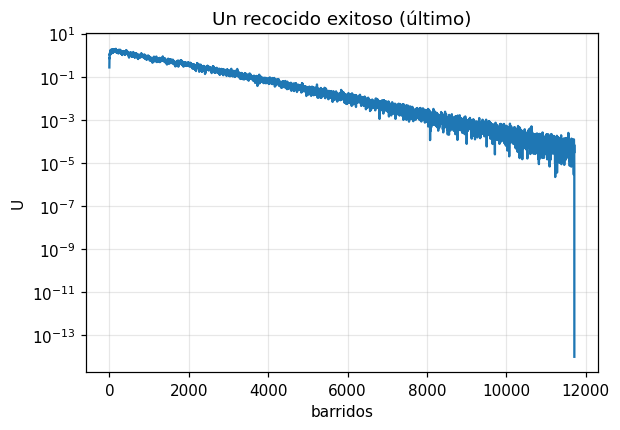

In [10]:
U_all = np.concatenate(historia)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].semilogy(np.maximum(U_all, 1e-14), lw=0.5)
for m in marcas: ax[0].axvline(m, color="gray", lw=0.2)
ax[0].set_xlabel("pasos de recocido (barridos acumulados)"); ax[0].set_ylabel("U (energía de traslape)")
ax[0].set_title("Evolución de la función objetivo (líneas grises: cambio de L)")
ax[1].plot(Ls_ok, "o-", ms=3)
ax[1].set_xlabel("intento exitoso #"); ax[1].set_ylabel("L"); ax[1].set_title("Lado de la caja aceptado")
plt.tight_layout(); plt.show()

# un único intento (el último exitoso) para ver el decaimiento de U dentro de un recocido
exito = [h for h in historia if h[-1] < 1e-12]
plt.figure(figsize=(6, 4)); plt.semilogy(np.maximum(exito[-1], 1e-14)); plt.xlabel("barridos"); plt.ylabel("U")
plt.title("Un recocido exitoso (último)"); plt.show()